# Projet SMA — notebook de rendu

Les deux parties et toutes les questions du starter sont conservées. Les réponses relisent les analyses et modèles réellement exécutés. Aucun entraînement n'est relancé à l'ouverture.

# Persons Involved in the Group

The five students are:
- Student 1
- Student 2
- Student 3
- Student 4
- Student 5

Les noms n'ont pas été fournis : les cinq champs du starter restent à compléter par l'équipe.

# Goal of this Practice

The goal is to study atmospheric heat waves in Brest (France) using statistical methods and recent machine learning approaches. First, the project will focus on historical data (1940-2025). Then, it will focus on the future (until 2100) under several CO2 emissions scenarios.

# Evaluation of this Practice

I will evaluate 3 main components:


1. the quality of the code (must be concise and well written)
2. the quality of the outputs (never forget that you are dealing with physical variables, so use the correct units)
3. the explanation of the method (describe mathematically the chosen approach, write directly into to notebook using Latex)
4. the discussion about your results (don't forget that data and results have a physical meaning)

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLAN_IMPLEMENTATION_MODELES_SMA.md").exists())
COMP = ROOT / "artifacts" / "competition"
FULL = ROOT / "artifacts" / "full_project"

def show_csv(path, rows=30):
    path = Path(path)
    if not path.exists():
        display(Markdown(f"**Artefact absent :** `{path.relative_to(ROOT)}`. Aucun résultat n'est revendiqué."))
        return pd.DataFrame()
    try:
        frame = pd.read_csv(path)
    except pd.errors.EmptyDataError:
        frame = pd.DataFrame()
    columns_by_name = {
        "validation_summary.csv": ["variable", "model", "crps", "twcrps", "coverage80", "width80", "bias", "brier", "fold_count"],
        "validation_mixture.csv": ["variable", "fold", "model", "tail_lambda", "crps", "twcrps"],
        "validation_individual.csv": ["variable", "fold", "model", "seed", "crps", "twcrps"],
        "test_diagnostics.csv": ["variable", "model", "crps", "twcrps", "coverage80", "width80", "bias", "brier"],
        "run_costs.csv": ["variable", "model_id", "fold", "seed", "steps", "best_step", "training_seconds", "gpu_memory_allocated_peak_bytes"],
        "residual_descriptive.csv": ["variable", "n", "skewness", "autocorrelation_lag1", "autocorrelation_lag2", "autocorrelation_lag3", "q05_C", "q50_C", "q95_C"],
        "bootstrap_dispersion.csv": ["variable", "model", "co2_ppm", "anchor_std_C", "generator_residual_std_C", "anchor_variance_fraction", "anchor_mean_shift_C"],
        "residual_law_diagnostics.csv": ["variable", "model", "mean_C", "std_C", "minimum_C", "q50_C", "maximum_C", "fraction_outside_central_window"],
        "bootstrap_block_sensitivity_summary.csv": ["variable", "model", "tail_lambda", "folds", "delta_crps_block1_minus3_C", "delta_twcrps_block1_minus3_C", "folds_global_block1_better", "folds_tail_block1_better"],
        "bootstrap_block_sensitivity_by_fold.csv": ["variable", "model", "fold", "tail_lambda", "delta_crps_block1_minus3_C", "delta_twcrps_block1_minus3_C"],
        "projection_summary.csv": ["variable", "scenario", "year", "co2", "q05", "q50", "q95", "event_probability"],
        "probability_40.csv": ["scenario", "k", "n", "probability", "ci_lower", "ci_upper", "resolution"],
        "trajectory_probability_40.csv": ["scenario", "k", "n", "probability", "ci_lower", "ci_upper"],
    }
    columns = [c for c in columns_by_name.get(path.name, frame.columns) if c in frame]
    display(frame[columns].head(rows).fillna("—"))
    display(Markdown(f"CSV complet : `{path.relative_to(ROOT)}`. Scores et largeurs en °C ; probabilités et couvertures sans unité."))
    if len(frame) > rows:
        display(Markdown(f"{len(frame)} lignes conservées dans le CSV complet."))
    return frame

def show_json(path):
    path = Path(path)
    if not path.exists():
        display(Markdown(f"**Artefact absent :** `{path.relative_to(ROOT)}`."))
        return {}
    record = json.loads(path.read_text(encoding="utf-8"))
    compact = record
    if path.name == "selection.json":
        compact = {key: record[key] for key in ("selected_models", "selected_tail_lambda", "final_steps") if key in record}
    elif path.name == "benchmark_results.json":
        compact = {"candidate": record.get("candidate"), "admissible_count": sum(bool(r.get("admissible")) for r in record.get("results", [])),
                   "results": [{"id": r.get("id"), "scores": r.get("scores"), "admissible": r.get("admissible"),
                                "errors": r.get("checks", {}).get("errors", [])} for r in record.get("results", [])]}
    display(Markdown("```json\n" + json.dumps(compact, ensure_ascii=False, indent=2) + "\n```"))
    display(Markdown(f"JSON complet : `{path.relative_to(ROOT)}`."))
    return record

def show_png(path):
    path = Path(path)
    if path.exists():
        display(Image(filename=str(path), width=1000))
    else:
        display(Markdown(f"**Figure absente :** `{path.relative_to(ROOT)}`."))

def show_figures(phase, names):
    for name in names:
        show_png(ROOT / "reports" / "figures" / phase / (name + ".png"))

def show_residuals(phase):
    display(Markdown(f"**Diagnostics résiduels descriptifs : phase {phase}.**"))
    frame = show_csv(ROOT / "artifacts" / phase / "annual_analysis" / "residual_descriptive.csv")
    if not frame.empty:
        import sys
        if str(ROOT / "src") not in sys.path:
            sys.path.insert(0, str(ROOT / "src"))
        from sma.reporting import residual_interpretation
        display(Markdown(residual_interpretation(frame)))
    return frame

def show_ddpm_failure():
    import sys
    if str(ROOT / "src") not in sys.path:
        sys.path.insert(0, str(ROOT / "src"))
    from sma.reporting import ddpm_failure_interpretation
    text = ddpm_failure_interpretation(ROOT)
    if text:
        text = text.replace("(diagnostic_echec_ddpm.md)", "(<" + (ROOT / "reports" / "diagnostic_echec_ddpm.md").as_posix() + ">)")
        display(Markdown(text))

def show_projected_events():
    path = FULL / "projection_summary.csv"
    if not path.exists():
        return show_csv(path)
    projected = pd.read_csv(path)
    columns = ["variable", "model", "scenario", "event_threshold_C", "event_probability", "event_definition", "n"]
    if {"year", *columns}.issubset(projected.columns):
        display(Markdown("**Probabilités marginales en 2100 :** Tmax > q80 ou Tmin < q20 de l’historique "
                         "1940–2025. Ces seuils descriptifs de la phase finale diffèrent des seuils de validation "
                         "et de test ajustés sur leurs trains. Les fréquences viennent des mêmes ensembles annuels "
                         "stockés, sans nouvelle simulation ; l’événement Tmax > 40 °C est présenté séparément."))
        display(projected.loc[projected.year == 2100, columns])
    return projected


# The ERA5 Database

**Paragraphe original du starter, provenance et résolution à vérifier :**

> Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

**Provenance contrôlée.** Le CSV et ses empreintes sont conservés dans `data/provenance_competition.json` et les audits. La mention 9 km du texte original n'est pas certifiée par ces fichiers. Il ne faut pas la présenter comme une résolution ERA5 vérifiée : ERA5-Land est un produit distinct. Aucune observation extérieure n'entre dans l'apprentissage.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

In [2]:
heatwaves = show_json(FULL / 'heatwaves' / 'heatwave_summary.json')
show_csv(FULL / 'heatwaves' / 'heatwave_daily_thresholds.csv', 5)

```json
{
  "phase": "full_project",
  "reference_start": "1940-01-01",
  "reference_end": "2025-12-31",
  "daily_rows": 31412,
  "missing_dates": 0,
  "feb29_days": 22,
  "climatology_days": 365,
  "smoothing_window_days": 31,
  "events_min3": 421,
  "events_min2": 798,
  "maximum_duration_min3_days": 14,
  "mean_intensity_min3_C": 3.587129639474805,
  "mean_excess_q90_min3_C": 1.1839315092731477,
  "units": "°C; duration in days",
  "event_definition": "maximal consecutive runs mean > smoothed q90",
  "intensity_definition": "event mean(mean temperature - smoothed q50)",
  "excess_definition": "event mean(mean temperature - smoothed q90)",
  "feb29_rule": "excluded from quantiles; thresholds interpolate February 28 / March 1",
  "interpretation": "descriptive climatology over supplied reference period; not out-of-sample prediction",
  "figures": [
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\heatwaves\\heatwave_seasonal_cycle.png",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\heatwaves\\heatwave_seasonal_cycle.svg",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\heatwaves\\heatwave_duration_intensity.png",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\heatwaves\\heatwave_duration_intensity.svg",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\heatwaves\\heatwave_counts.png",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\heatwaves\\heatwave_counts.svg"
  ]
}
```

JSON complet : `artifacts\full_project\heatwaves\heatwave_summary.json`.

,valid_time,mean,month_day,q10_smooth,q50_smooth,q90_smooth
0,1940-01-01,3.484619,01-01,3.886541,8.621719,11.402501
1,1940-01-02,2.409851,01-02,3.869559,8.586937,11.354092
2,1940-01-03,6.619751,01-03,3.834313,8.534988,11.304110
3,1940-01-04,7.831360,01-04,3.822978,8.500733,11.279746
4,1940-01-05,8.317627,01-05,3.789981,8.461679,11.275543


CSV complet : `artifacts\full_project\heatwaves\heatwave_daily_thresholds.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

31412 lignes conservées dans le CSV complet.

,valid_time,mean,month_day,q10_smooth,q50_smooth,q90_smooth
0,1940-01-01,3.484619,01-01,3.886541,8.621719,11.402501
1,1940-01-02,2.409851,01-02,3.869559,8.586937,11.354092
2,1940-01-03,6.619751,01-03,3.834313,8.534988,11.304110
3,1940-01-04,7.831360,01-04,3.822978,8.500733,11.279746
4,1940-01-05,8.317627,01-05,3.789981,8.461679,11.275543
...,...,...,...,...,...,...
31407,2025-12-27,5.816040,12-27,4.194607,8.787404,11.567689
31408,2025-12-28,5.751068,12-28,4.127849,8.760335,11.536342
31409,2025-12-29,5.455261,12-29,4.041517,8.726836,11.494694
31410,2025-12-30,5.287292,12-30,3.962739,8.690179,11.464210


Compute the seasonal cycle of the mean temperature in Brest. To do so, for each day of the year (between 1 and 365), compute the quantiles at 10%, 50%, and 90%. Apply a 1-month rolling mean to smooth the data. Plot the corresponding curves and comment on this figure.

Calendrier de 365 jours par mois/jour ; 29 février exclu des quantiles. Moyenne circulaire de 31 jours (15 jours avant/après) ; seuil du 29 février interpolé entre 28 février et 1er mars. La référence finale 1940–2025 est descriptive ; sa version 1940–2000 a été utilisée durant le développement.

,month_day,q10,q50,q90,day_climatology,q10_smooth,q50_smooth,q90_smooth
0,01-01,3.657928,8.790482,11.224854,1,3.886541,8.621719,11.402501
1,01-02,3.566788,8.290710,11.421478,2,3.869559,8.586937,11.354092
2,01-03,3.763153,7.697571,11.346771,3,3.834313,8.534988,11.304110
3,01-04,3.946030,8.164917,11.304352,4,3.822978,8.500733,11.279746
4,01-05,3.637344,8.718399,11.225861,5,3.789981,8.461679,11.275543


CSV complet : `artifacts\full_project\heatwaves\heatwave_climatology.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

365 lignes conservées dans le CSV complet.

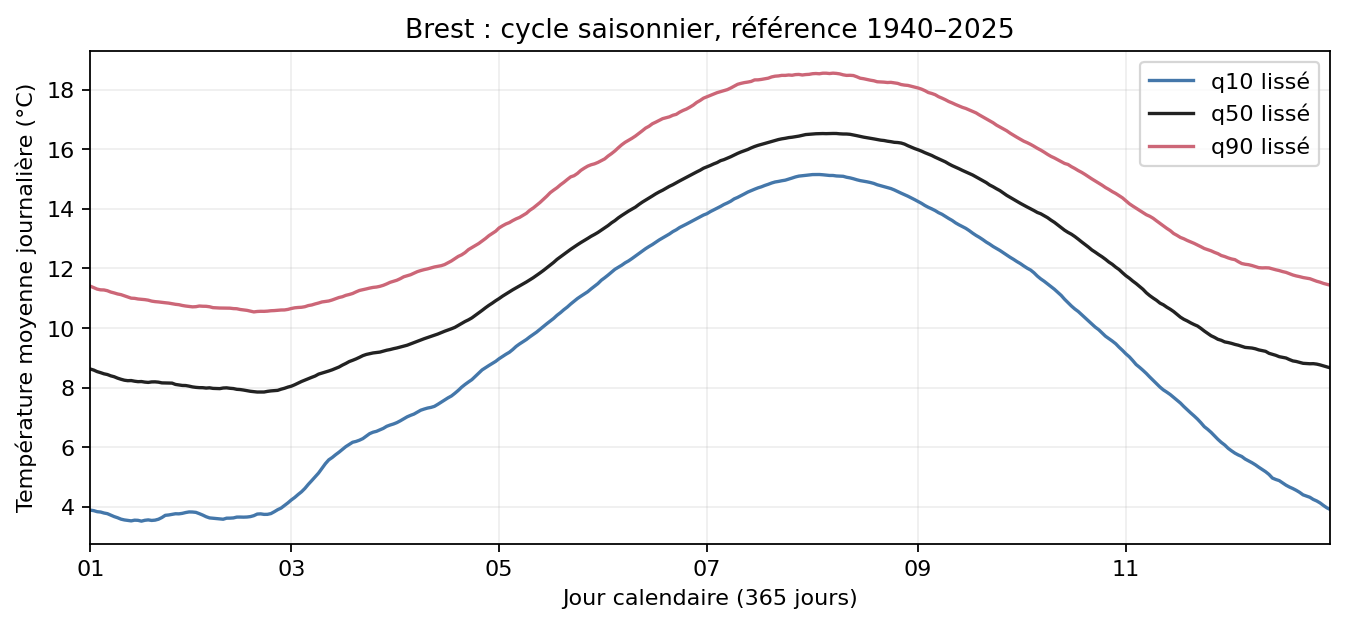

La médiane saisonnière lissée varie de 7.85 °C à 16.53 °C, avec un maximum vers 08-07.

In [3]:
climatology = show_csv(FULL / 'heatwaves' / 'heatwave_climatology.csv', 5)
show_png(FULL / 'heatwaves' / 'heatwave_seasonal_cycle.png')
if not climatology.empty:
    peak = climatology.loc[climatology.q50_smooth.idxmax()]
    trough = climatology.loc[climatology.q50_smooth.idxmin()]
    display(Markdown(f'La médiane saisonnière lissée varie de {trough.q50_smooth:.2f} °C à {peak.q50_smooth:.2f} °C, avec un maximum vers {peak.month_day}.'))

Compute the duration and intensity of the different heat waves during the period 1940 to 2025. The duration corresponds to the number of consecutive days exceeding the 90% quantile. The intensity is defined as the mean temperature anomaly during those consecutive days.

L'événement est une suite **maximale** de jours où $T_{mean}>q_{90,lissé}$. La durée principale minimale est 3 jours ; une sensibilité à 2 jours est sauvegardée. L'intensité est $\overline{T_{mean}-q_{50,lissé}}$ (°C) ; l'excès moyen au-dessus du seuil est $\overline{T_{mean}-q_{90,lissé}}$ (°C). La continuité utilise les dates réelles, y compris le 29 février.

In [4]:
events = show_csv(FULL / 'heatwaves' / 'heatwave_events_min3.csv', 15)
sensitivity = show_csv(FULL / 'heatwaves' / 'heatwave_events_min2.csv', 5)
counts = show_csv(FULL / 'heatwaves' / 'heatwave_counts_year.csv', 10)
if not events.empty:
    display(Markdown(f'{len(events)} événements de durée minimale 3 jours ; durée maximale {events.duration_days.max()} jours. Anomalie moyenne des événements à q50 : {events.intensity_q50_C.mean():.3f} °C ; excès moyen à q90 : {events.excess_q90_C.mean():.3f} °C. Ces moyennes donnent le même poids à chaque événement.'))

,start,end,duration_days,intensity_q50_C,excess_q90_C,start_year,max_mean_C
0,1940-04-21,1940-04-23,3,3.512399,1.169434,1940,14.454346
1,1940-05-07,1940-05-10,4,3.054752,0.744284,1940,15.476807
2,1940-06-03,1940-06-08,6,6.097487,3.739988,1940,20.725769
3,1940-09-01,1940-09-04,4,3.083762,1.007921,1940,19.714722
4,1941-07-01,1941-07-03,3,2.580000,0.230999,1941,18.134888
5,1942-03-11,1942-03-14,4,2.896296,0.545591,1942,11.902710
6,1942-06-03,1942-06-06,4,5.172597,2.825741,1942,19.778961
7,1942-09-10,1942-09-13,4,3.549236,1.447685,1942,19.569153
8,1942-10-02,1942-10-04,3,2.772030,0.615424,1942,17.218811
9,1942-12-09,1942-12-11,3,3.353266,0.588797,1942,13.375000


CSV complet : `artifacts\full_project\heatwaves\heatwave_events_min3.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

421 lignes conservées dans le CSV complet.

,start,end,duration_days,intensity_q50_C,excess_q90_C,start_year,max_mean_C
0,1940-03-17,1940-03-18,2,3.181017,0.912987,1940,12.810974
1,1940-04-21,1940-04-23,3,3.512399,1.169434,1940,14.454346
2,1940-05-07,1940-05-10,4,3.054752,0.744284,1940,15.476807
3,1940-06-03,1940-06-08,6,6.097487,3.739988,1940,20.725769
4,1940-08-03,1940-08-04,2,2.630322,0.613223,1940,19.525085


CSV complet : `artifacts\full_project\heatwaves\heatwave_events_min2.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

798 lignes conservées dans le CSV complet.

,year,events_min3,days_min3,events_min2,days_min2
0,1940,4,17,6,21
1,1941,1,3,8,17
2,1942,5,18,9,26
3,1943,3,12,8,22
4,1944,4,16,7,22
5,1945,6,29,12,41
6,1946,4,19,5,21
7,1947,8,39,12,47
8,1948,5,18,12,32
9,1949,8,33,16,49


CSV complet : `artifacts\full_project\heatwaves\heatwave_counts_year.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

86 lignes conservées dans le CSV complet.

421 événements de durée minimale 3 jours ; durée maximale 14 jours. Anomalie moyenne des événements à q50 : 3.587 °C ; excès moyen à q90 : 1.184 °C. Ces moyennes donnent le même poids à chaque événement.

Make the following scatter plot of the heat waves in Brest, with: x-axis representing duration, y-axis representing intensity, and the color representing the year of appearance. Comment on this figure.

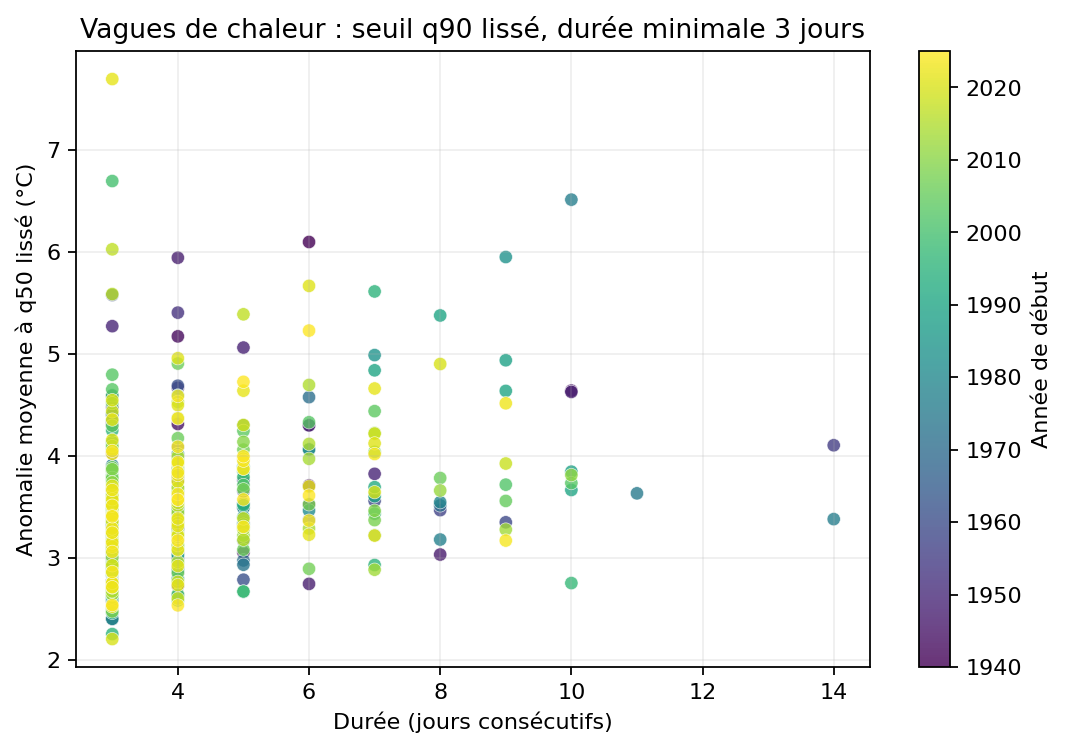

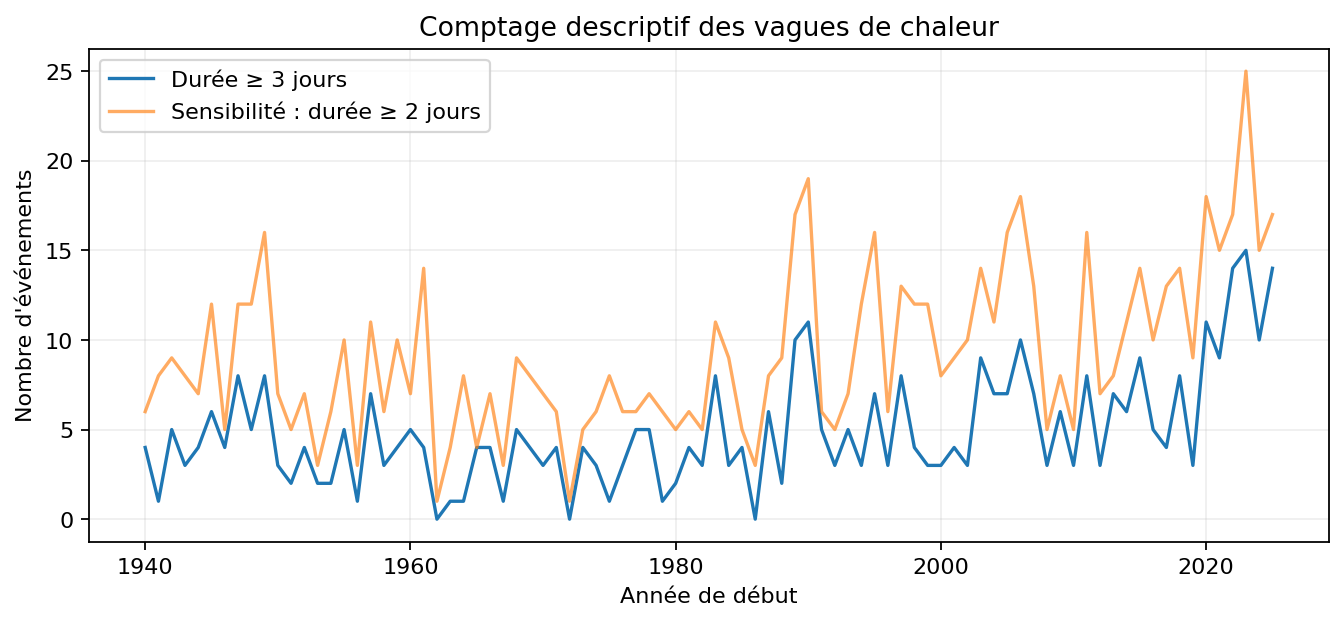

La couleur indique l’année de début, la durée le nombre de jours calendaires consécutifs. Les seuils sont saisonniers : un épisode hivernal doux peut être détecté. Le diagramme décrit la variabilité et ne démontre pas une causalité ou une calibration prédictive.

In [5]:
show_png(FULL / 'heatwaves' / 'heatwave_duration_intensity.png')
show_png(FULL / 'heatwaves' / 'heatwave_counts.png')
display(Markdown('La couleur indique l’année de début, la durée le nombre de jours calendaires consécutifs. Les seuils sont saisonniers : un épisode hivernal doux peut être détecté. Le diagramme décrit la variabilité et ne démontre pas une causalité ou une calibration prédictive.'))

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

In [6]:
annual = show_csv(FULL / 'annual_analysis' / 'annual_descriptive.csv', 8)
annual_summary = show_json(FULL / 'annual_analysis' / 'annual_summary.json')

,valid_time,max,min,co2,year,anchor_max,residual_max,standardized_max,anchor_min,residual_min,standardized_min
0,1940-01-01,24.790497,-3.994019,310.000000,1940,24.579269,0.211228,0.096589,-1.190088,-2.803931,-1.467943
1,1941-01-01,24.934845,-1.216583,311.162500,1941,24.606989,0.327856,0.149920,-1.178826,-0.037758,-0.019767
2,1942-01-01,25.541260,-1.027679,312.329359,1942,24.634708,0.906551,0.414541,-1.167564,0.139884,0.073234
3,1943-01-01,27.316742,1.669037,313.500594,1943,24.662428,2.654314,1.213744,-1.156302,2.825339,1.479151
4,1944-01-01,25.795715,-0.246552,314.676222,1944,24.690148,1.105567,0.505545,-1.145040,0.898489,0.470386
5,1945-01-01,24.527527,-0.697418,315.856258,1945,24.717868,-0.190341,-0.087038,-1.133778,0.436360,0.228448
6,1946-01-01,24.271851,-1.858795,317.040718,1946,24.745587,-0.473737,-0.216627,-1.122516,-0.736279,-0.385464
7,1947-01-01,27.949127,-4.575195,318.229621,1947,24.773307,3.175820,1.452214,-1.111254,-3.463941,-1.813478


CSV complet : `artifacts\full_project\annual_analysis\annual_descriptive.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

86 lignes conservées dans le CSV complet.

```json
{
  "phase": "full_project",
  "years_start": 1940,
  "years_end": 2025,
  "n_years": 86,
  "anchor": {
    "max": {
      "a": -17.90458623186814,
      "b": 7.405790925722071,
      "b_raw": 7.405790925722071,
      "sigma": 2.18688131320709,
      "sigma_raw": 2.18688131320709,
      "scale_floor_active": false,
      "n": 86,
      "log_co2_center": 5.895713966151757,
      "constraint_active": false
    },
    "min": {
      "a": -18.450285112377134,
      "b": 3.008799785977186,
      "b_raw": 3.008799785977186,
      "sigma": 1.9101088092391612,
      "sigma_raw": 1.9101088092391612,
      "scale_floor_active": false,
      "n": 86,
      "log_co2_center": 5.895713966151757,
      "constraint_active": false
    }
  },
  "figures": [
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\annual_analysis\\annual_observations_anchor.png",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\annual_analysis\\annual_observations_anchor.svg",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\annual_analysis\\annual_correlations.png",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\annual_analysis\\annual_correlations.svg",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\annual_analysis\\annual_residual_diagnostics.png",
    "C:\\Users\\edlas\\OneDrive\\Documents\\ChatGPT\\Mini projet stochastique\\artifacts\\full_project\\annual_analysis\\annual_residual_diagnostics.svg"
  ],
  "interpretation": "descriptive fitted in supplied period; not validation predictions"
}
```

JSON complet : `artifacts\full_project\annual_analysis\annual_summary.json`.

Plot and comment on the maximum annual temperature in Brest from 1940 to 2025.

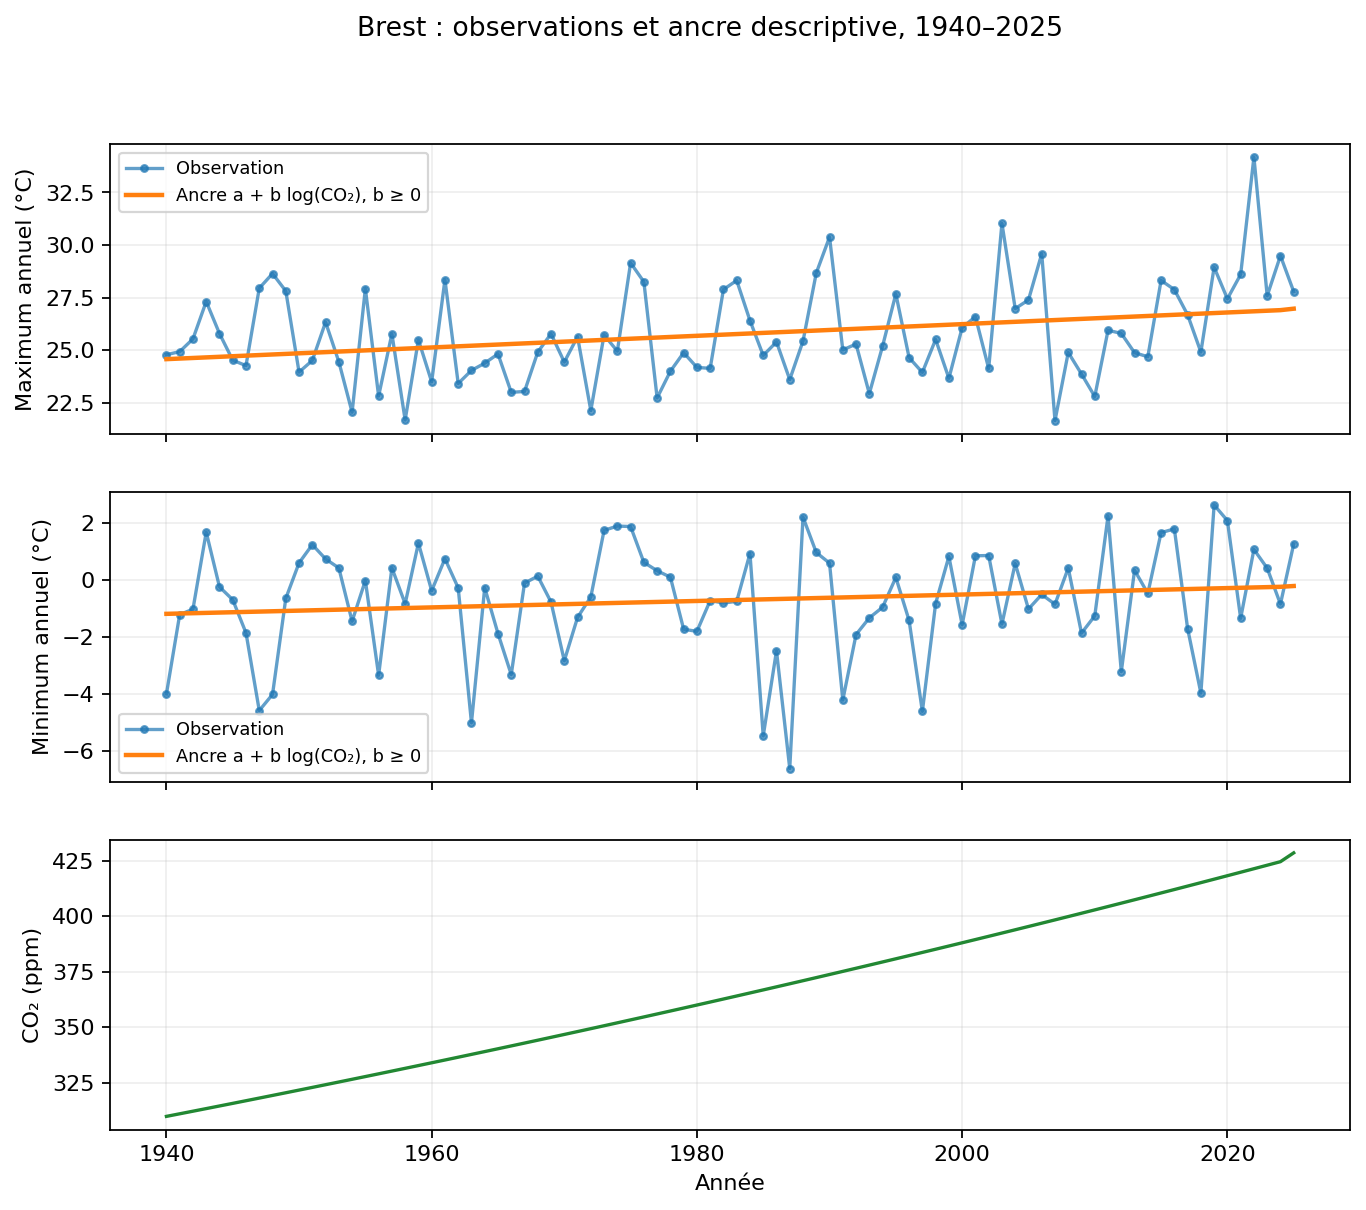

Les maxima annuels observés vont de 21.66 à 34.18 °C. L’ancre représente une tendance en fonction du CO₂ ; les fluctuations annuelles restent importantes.

In [7]:
show_png(FULL / 'annual_analysis' / 'annual_observations_anchor.png')
if not annual.empty:
    display(Markdown(f'Les maxima annuels observés vont de {annual["max"].min():.2f} à {annual["max"].max():.2f} °C. L’ancre représente une tendance en fonction du CO₂ ; les fluctuations annuelles restent importantes.'))

Compute the correlation between the maximum annual temperature in Brest and the global annual CO2. To increase the linear correlation coefficient, test several transformations of those two variables.

,phase,variable,transformation,n,pearson_r,p_descriptive
0,full_project,max,CO2,86,0.314326,0.003205
1,full_project,max,log(CO2),86,0.303713,0.004472
2,full_project,min,CO2,86,0.150344,0.167063
3,full_project,min,log(CO2),86,0.146671,0.177796


CSV complet : `artifacts\full_project\annual_analysis\correlations.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

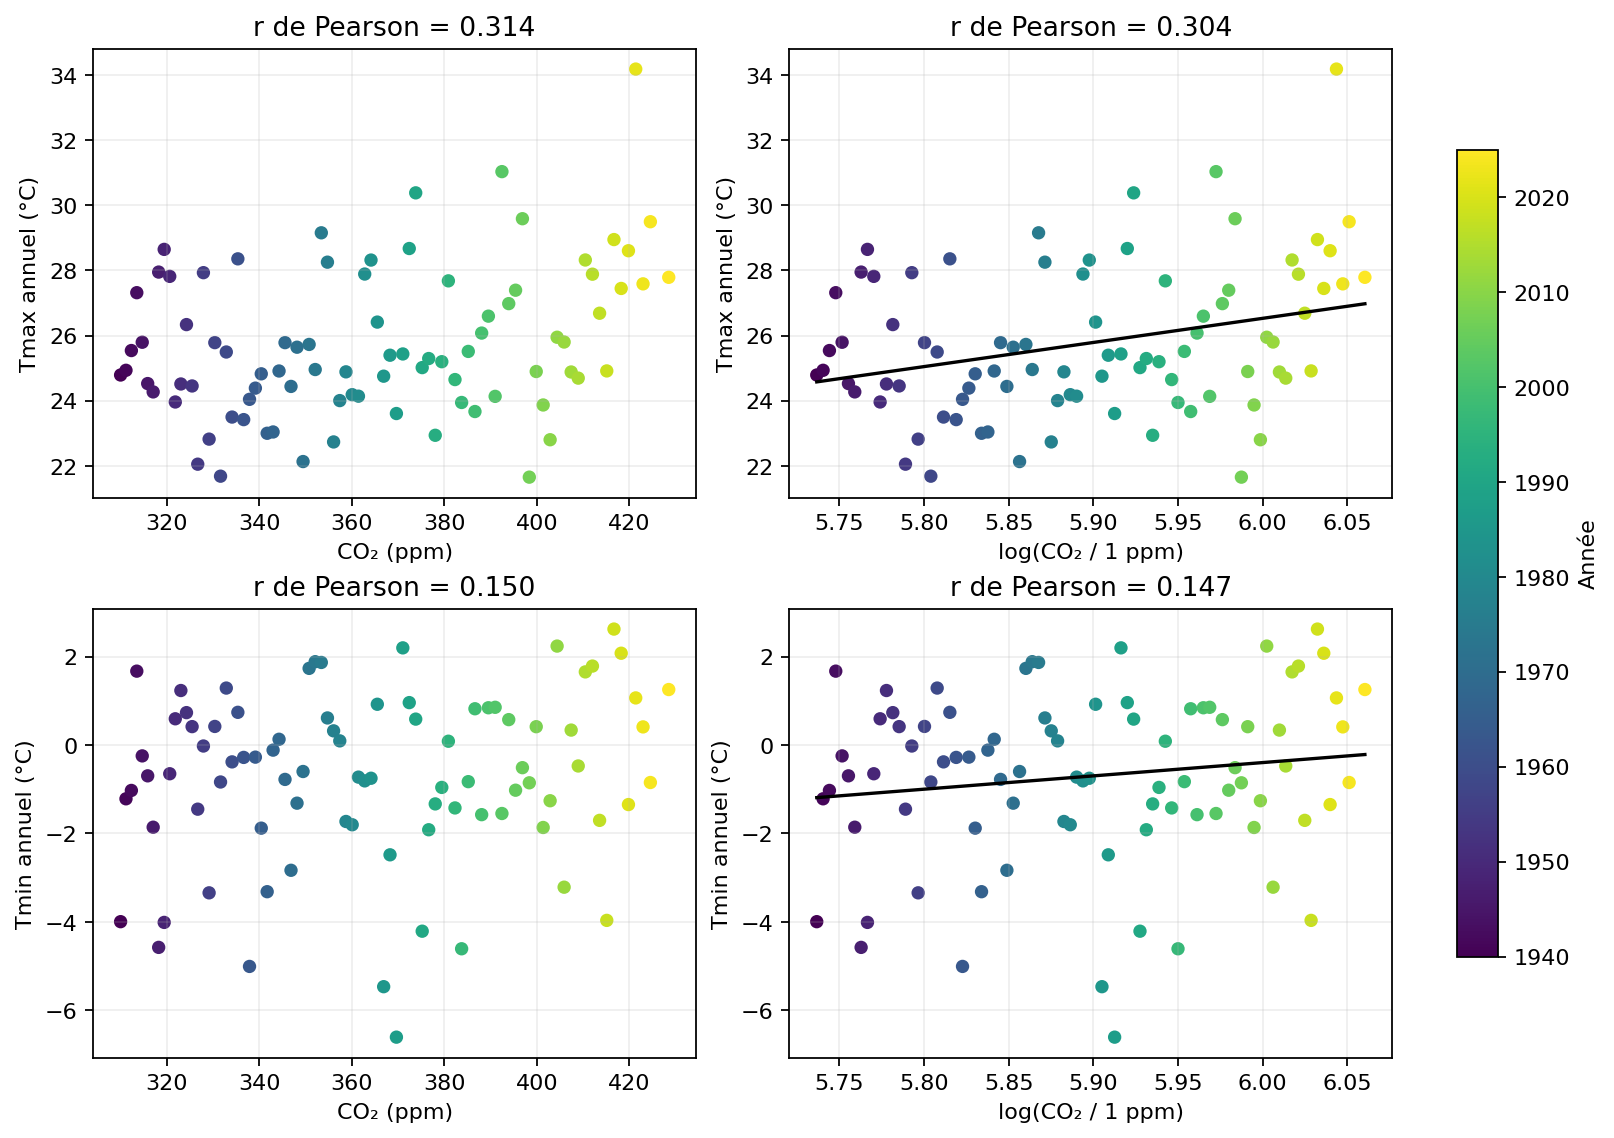

Nous comparons CO₂ brut et log(CO₂), sans transformer la cible thermique. La transformation logarithmique correspond à l’ancre retenue ; une meilleure corrélation descriptive ne prouve ni une causalité locale complète, ni une meilleure extrapolation. Aucune moyenne mobile centrée de températures futures n’entre dans la prévision.

In [8]:
correlations = show_csv(FULL / 'annual_analysis' / 'correlations.csv')
show_png(FULL / 'annual_analysis' / 'annual_correlations.png')
display(Markdown('Nous comparons CO₂ brut et log(CO₂), sans transformer la cible thermique. La transformation logarithmique correspond à l’ancre retenue ; une meilleure corrélation descriptive ne prouve ni une causalité locale complète, ni une meilleure extrapolation. Aucune moyenne mobile centrée de températures futures n’entre dans la prévision.'))

Use recent machine learning methods to provide probabilistic predictions (not deterministic) of maximum annual temperatures until 2100, conditionally on the three main climate scenarios. These SSPs differ in their level of annual CO2 emissions. Do not forget to present your approach mathematically and to justify your choice.


## Méthodes et conventions mathématiques

L'ancre est ajustée séparément pour Tmax et Tmin : $Y=a+b\log(C)+R$, avec $b=\max(b_{OLS},0)$,
$a=\overline{Y-b\log(C)}$, $\sigma=\mathrm{sd}(R,ddof=2)$ et $Z=R/\sigma$. Le CO₂ est exprimé
en ppm et les résultats en °C. La contrainte traduit ici une hypothèse de tendance locale monotone.
Elle ne démontre pas une réponse physique universelle. La loi résiduelle est supposée stationnaire.

R0 utilise $R\sim\mathcal N(0,\sigma^2)$ ; R1 ajuste une GEV à R pour Tmax, à −R pour Tmin,
avec la convention SciPy $c=-\xi$. R2 rééchantillonne les résidus. Le support GEV et les échecs
d'admissibilité doivent être examinés même si le score moyen semble favorable.
La reproduction exacte R0_exact suit les quatre appels RNG originaux
(test_max, test_min, proj_max, proj_min) : ses résidus sont indépendants entre scénarios.
Les autres exports réutilisent les mêmes résidus et, lorsqu'elle varie, la même ancre entre scénarios.

Le DDPM D0 apprend le bruit dans $Z_k=\sqrt{\bar\alpha_k}Z+\sqrt{1-\bar\alpha_k}\epsilon$ par MSE,
avec 100 pas et un calendrier cosinus. Sa génération suit le processus ancestral inverse. D1 produit
$\hat Z_m=g_\phi(u,t,\zeta_m)$ avec $u=(1-t)Z+t\epsilon$. Dans un ensemble d'entraînement,
u et t sont communs, les latents $\zeta_m$ indépendants ; l'inférence utilise t=1, sans observation
future. C0 emploie le même générateur avec u=0, t=1, pour mesurer l'apport du débruitage auxiliaire.
Il s'agit d'une adaptation scalaire d'une méthode météorologique récente, et non d'une validation
de cette publication sur Brest.

Pour D0, $L_{MSE}=\mathbb E[(\epsilon-\epsilon_\phi(Z_k,k/K))^2]$. En génération :

$$
Z_{k-1}=\frac{1}{\sqrt{\alpha_k}}\left(Z_k-
\frac{\beta_k}{\sqrt{1-\bar\alpha_k}}\epsilon_\phi(Z_k,k/K)\right)
+\sqrt{\tilde\beta_k}\eta,\qquad
\tilde\beta_k=\beta_k\frac{1-\bar\alpha_{k-1}}{1-\bar\alpha_k}.
$$

Le dernier pas ne rajoute aucun bruit. Le calendrier cosinus utilise s=0,008, beta ≤ 0,999,
et son alpha_bar terminal est inférieur à 10⁻³. Les calendriers sont dans les checkpoints.

Le CRPS d'évaluation est $N^{-1}\sum_m|x_m-y|-(2N^2)^{-1}\sum_{m,n}|x_m-x_n|$,
calculé par tri en float64. L'apprentissage C0/D1/D2 utilise M=32 et
$afCRPS=0.95\,fCRPS+0.05\,CRPS_{emp}$, où le terme de dispersion fair a le dénominateur
$2M(M-1)$. Ce petit mélange est légèrement biaisé et diffère du score empirique officiel.
D2 ajoute $\lambda\,afCRPS(h(\hat Y),h(Y))$, avec la même convention
$afCRPS=0.95\,fCRPS+0.05\,CRPS_{emp}$ que le terme global, et
$h(x)=\max(x,s_{hot})$ pour Tmax et
$h(x)=\min(x,s_{cold})$ pour Tmin. Ces seuils sont les quantiles 0,80/0,20 du train.
Le twCRPS d'évaluation applique seulement cette transformation au calcul du score : aucun tirage
de température n'est écrêté. Toutes les années comptent, y compris les fausses alertes.

D3 et D4 réutilisent les réseaux de D1/D2 et ajoutent un bootstrap résiduel de l'ancre à CO₂ fixé
(500 réplications, blocs circulaires de 3 ans ; sensibilité longueur 1). L'échelle et la loi neuronale
restent fixes : cette approximation ne mesure pas toute l'incertitude des paramètres. Elle n'est pas
un posterior bayésien. Le même couple ancre/résidu est employé entre scénarios d'une année.

La contrainte $b\geq0$ peut aussi décaler la moyenne des ancres bootstrap vers le haut lors de
l'extrapolation. L'ajout n'agit donc pas seulement sur la largeur : le tableau de dispersion
rapporte également le décalage moyen par rapport à l'ancre ponctuelle. Un gain de CRPS ne
doit pas être attribué automatiquement à la seule représentation de l'incertitude.

Les intervalles sont centraux, à 50/80/90 %, avec couverture inclusive et largeur en °C.
Le PIT est $(\#\{x_m<y\}+0.5\#\{x_m=y\})/N$, un rang médian déterministe adapté aux égalités
de R2. Le Brier utilise les événements stricts Tmax>s ou Tmin<s. Le biais est la moyenne de
$E_F(Y)-y$, la MAE celle de la médiane. Un PIT de 25 points ne certifie pas une calibration.

## Portée physique et limites

Les températures moyennes journalières servent aux vagues de chaleur ; leurs maxima ne remplacent
pas les extrêmes horaires du fichier annuel. Les 61 puis 86 années restent le nombre d'observations
annuelles : le bruit d'entraînement et 10 000 simulations n'ajoutent aucune observation climatique.
Le CO₂ décrit une tendance mondiale et ne suffit pas à établir une causalité locale complète :
variabilité atmosphérique et océanique, autres forçages et état local ne sont pas explicitement modélisés.

Un bon CRPS sur 25 années évalue surtout la loi dans la région observée. Il ne valide pas la queue
à 40 °C, ni l'extrapolation jusqu'à un CO₂ très supérieur au domaine historique. Les paramètres GEV,
la stationnarité résiduelle et la forme log-linéaire sont fragiles avec ce petit échantillon. Les bornes
du kit et ses tests de monotonie/largeur sont des conventions du groupe, pas des lois physiques.

Il faut distinguer : erreur Monte-Carlo (nombre fini de simulations, conditionnel au modèle ajusté),
incertitude d'estimation (ancre et poids appris) et erreur de modèle (tendance, queue, dynamique).
Le bootstrap d'ancre ne traite que la première composante paramétrique de la tendance.
Une probabilité d'au moins un dépassement durant 2026–2100 exige une hypothèse de dépendance :
résidus indépendants conditionnellement à l'ancre, avec la même ancre conservée sur la trajectoire.
La formule $1-\prod_t(1-p_t)$ pour des marges n'est pas valide avec une ancre aléatoire partagée.


Les fichiers fournis contiennent des **concentrations** annuelles de CO₂ en ppm. Elles servent de covariable ; il ne s'agit pas d'un flux annuel d'émissions. Le meilleur modèle statistique peut gagner. La méthode neuronale reste expliquée et évaluée pour répondre au volet récent de machine learning ; aucun gain n'est garanti.

In [9]:
projection_path = FULL / 'projections.npz'
if projection_path.exists():
    with np.load(projection_path, allow_pickle=False) as projected:
        display(Markdown(f'Ensembles disponibles : Tmax {projected["max"].shape}, Tmin {projected["min"].shape}. Années {projected["years"][0]}–{projected["years"][-1]}.'))
        if 'co2' in projected:
            display(pd.DataFrame({'scenario': projected['scenarios'], 'co2_2026_ppm': projected['co2'][:, 0], 'co2_2100_ppm': projected['co2'][:, -1]}))
transition = show_json(FULL / 'co2_transition.json')

Ensembles disponibles : Tmax (3, 75, 10000), Tmin (3, 75, 10000). Années 2026–2100.

,scenario,co2_2026_ppm,co2_2100_ppm
0,ssp1-2.6,420.780225,400.000000
1,ssp2-4.5,420.188542,526.987384
2,ssp5-8.5,421.121677,946.222152


```json
{
  "historical_2025_co2": 428.5017353613867,
  "scenario_2026_co2": {
    "ssp1-2.6": 420.78022467656336,
    "ssp2-4.5": 420.18854219474224,
    "ssp5-8.5": 421.1216772259265
  },
  "difference_ppm": {
    "ssp1-2.6": -7.721510684823329,
    "ssp2-4.5": -8.313193166644453,
    "ssp5-8.5": -7.380058135460217
  },
  "scenario_2100_co2": {
    "ssp1-2.6": 400.0,
    "ssp2-4.5": 526.9873843407519,
    "ssp5-8.5": 946.2221518449436
  },
  "trajectories_changed": false,
  "interpretation": "CO₂ fourni de tendance, non une observation causale locale complète; rupture conservée telle quelle."
}
```

JSON complet : `artifacts\full_project\co2_transition.json`.

```json
{
  "selected_models": {
    "max": "C0_direct_crps",
    "min": "D1_ddm_crps"
  },
  "selected_tail_lambda": {
    "max": 0.5,
    "min": 0.5
  },
  "final_steps": {
    "max": {
      "C0_direct_crps": 2750,
      "D0_ddpm": 2750,
      "D1_ddm_crps": 1250,
      "D2_ddm_tail_lambda0.5": 750,
      "D2_ddm_tail_lambda1": 750,
      "D2_ddm_tail_lambda2": 750
    },
    "min": {
      "C0_direct_crps": 2500,
      "D0_ddpm": 1250,
      "D1_ddm_crps": 1500,
      "D2_ddm_tail_lambda0.5": 1250,
      "D2_ddm_tail_lambda1": 1000,
      "D2_ddm_tail_lambda2": 1000
    }
  }
}
```

JSON complet : `artifacts\competition\selection.json`.

,variable,model,crps,twcrps,coverage80,width80,bias,brier,fold_count
0,max,C0_direct_crps,1.142265,0.403289,0.733333,5.144457,-0.206869,0.166280,3
1,max,D0_ddpm,1.097160,0.389177,0.766667,5.140041,-0.273135,0.153721,3
2,max,D1_ddm_crps,1.120387,0.386446,0.800000,5.492069,-0.113684,0.155856,3
3,max,D2_ddm_tail_lambda0.5,1.121605,0.385844,0.800000,5.515968,-0.128532,0.155961,3
4,max,D2_ddm_tail_lambda1,1.125073,0.386949,0.800000,5.447067,-0.149970,0.155696,3
5,max,D2_ddm_tail_lambda2,1.141764,0.391472,0.800000,5.632326,-0.227321,0.158266,3
6,max,D3_ddm_anchor,1.110931,0.378243,0.833333,5.651930,0.079950,0.156330,3
7,max,D4_ddm_tail_anchor_lambda0.5,1.111625,0.377714,0.833333,5.677580,0.065102,0.156210,3
8,max,D4_ddm_tail_anchor_lambda1,1.114176,0.378202,0.800000,5.621393,0.043664,0.155756,3
9,max,D4_ddm_tail_anchor_lambda2,1.127501,0.382432,0.800000,5.799409,-0.033687,0.158433,3


CSV complet : `artifacts\competition\validation_summary.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

Meilleure variante neuronale pour Tmax en validation : **D0_ddpm**, CRPS 1.097160 °C. La règle fixée de complexité s’applique aux scores proches ; l’admissibilité est contrôlée ensuite sans température de test.

Meilleure variante neuronale pour Tmin en validation : **D0_ddpm**, CRPS 1.143005 °C. La règle fixée de complexité s’applique aux scores proches ; l’admissibilité est contrôlée ensuite sans température de test.

,variable,scenario,year,co2,q05,q50,q95,event_probability
0,max,ssp1-2.6,2026,420.780225,23.765833,26.630407,30.958123,0.2916
1,max,ssp1-2.6,2027,421.558613,23.779520,26.644094,30.971811,0.2944
2,max,ssp1-2.6,2028,422.333331,23.793118,26.657691,30.985408,0.2966
3,max,ssp1-2.6,2029,423.102552,23.806594,26.671168,30.998884,0.2984
4,max,ssp1-2.6,2030,423.864459,23.819918,26.684492,31.012208,0.3002
5,max,ssp1-2.6,2031,424.617247,23.833059,26.697633,31.025350,0.3016
6,max,ssp1-2.6,2032,425.359128,23.845987,26.710561,31.038277,0.3035
7,max,ssp1-2.6,2033,426.088333,23.858672,26.723246,31.050963,0.3050
8,max,ssp1-2.6,2034,426.803114,23.871086,26.735659,31.063376,0.3066


CSV complet : `artifacts\full_project\projection_summary.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

450 lignes conservées dans le CSV complet.

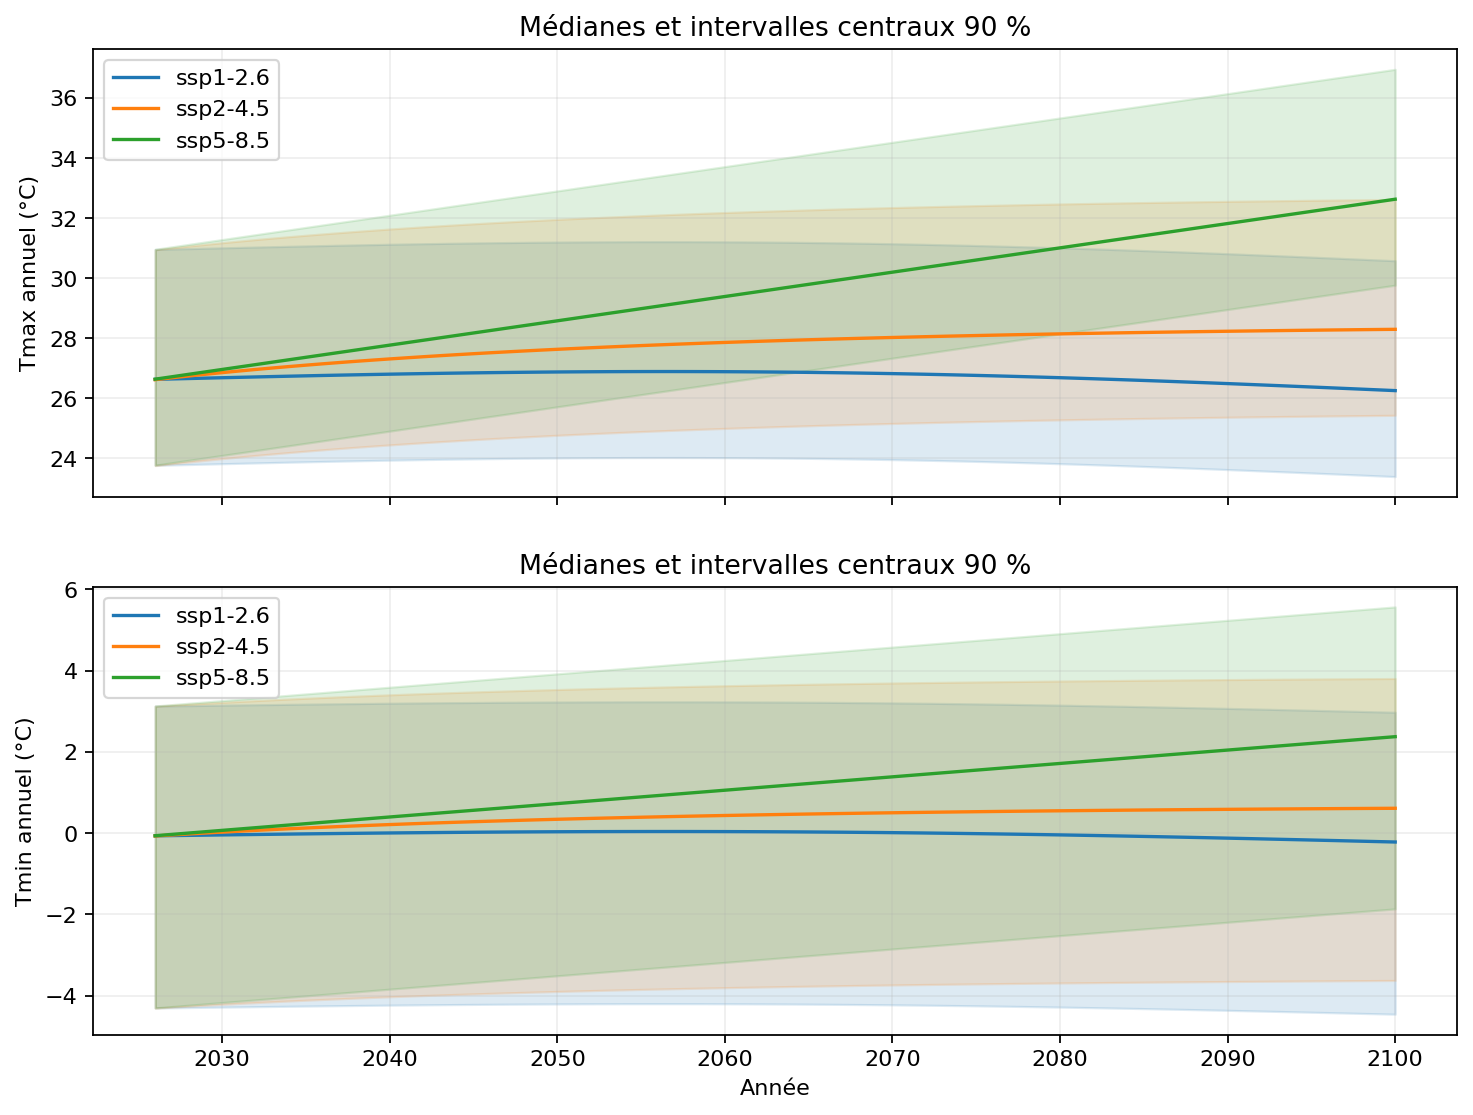

In [10]:
selection = show_json(COMP / 'selection.json')
validation = show_csv(COMP / 'validation_summary.csv')
if not validation.empty:
    for variable in ['max', 'min']:
        view = validation[validation.variable == variable].sort_values('crps')
        neural = view[view.model.astype(str).str.startswith(('D', 'C0'))]
        if not neural.empty:
            best = neural.iloc[0]
            display(Markdown(f'Meilleure variante neuronale pour T{variable} en validation : **{best.model}**, CRPS {best.crps:.6f} °C. La règle fixée de complexité s’applique aux scores proches ; l’admissibilité est contrôlée ensuite sans température de test.'))
show_csv(FULL / 'projection_summary.csv', 9)
show_figures('full_project', ['projection_trajectories'])

Based on your probabilistic predictions, provide the distribution of the maximum annual temperature in 2100 for the three climate scenarios (SSPs). Based on your predictions, what is the probability of exceeding 40°C in Brest, by 2100, for the three climate scenarios?

Le résultat principal concerne **Tmax en 2100**. La probabilité d'au moins un dépassement durant 2026–2100 est un résultat distinct qui exige une hypothèse temporelle. Les quotas fixes du mélange officiel sont stratifiés ; un calcul binomial utilise un ensemble supplémentaire avec l'indice de réseau tiré indépendamment à chaque simulation.

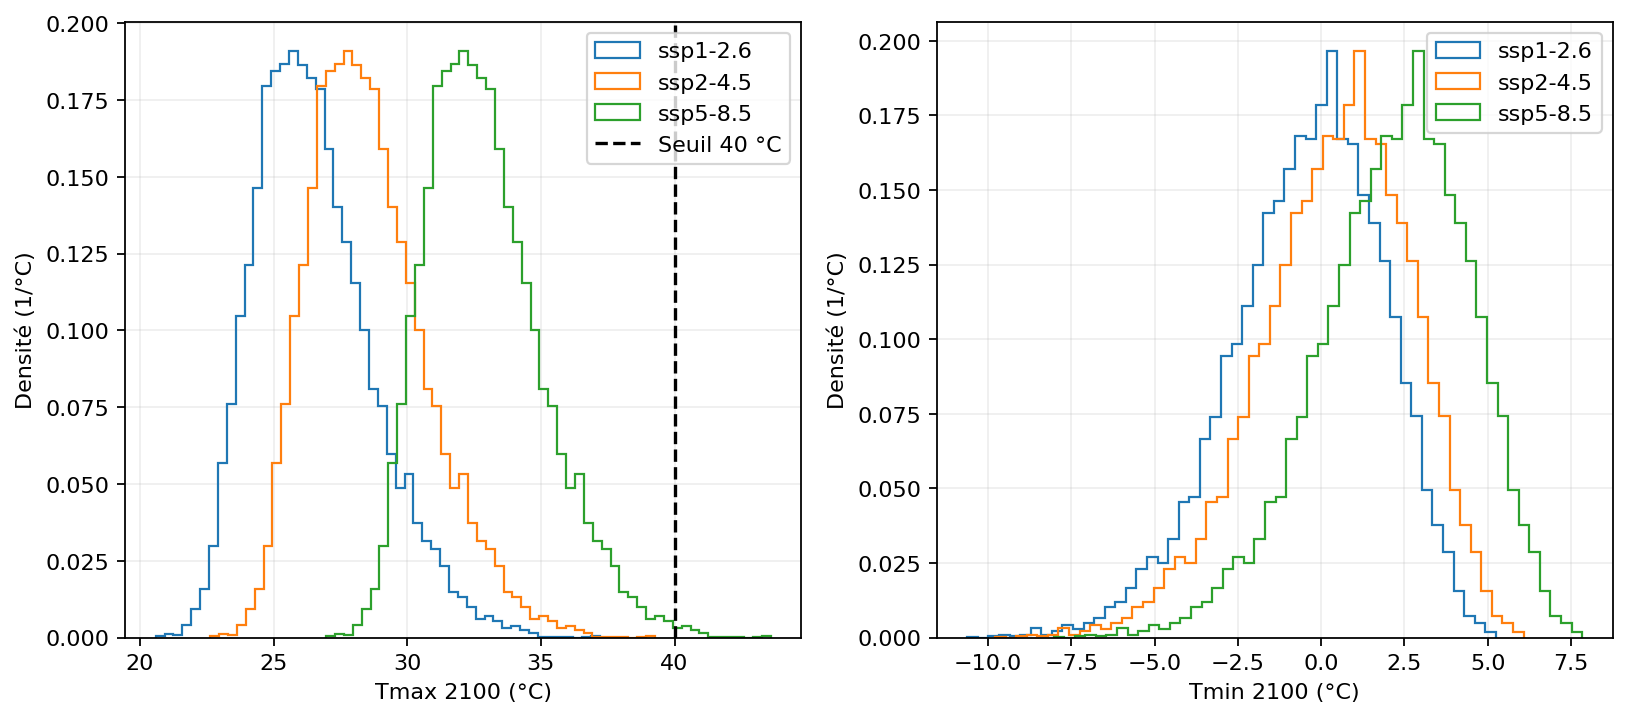

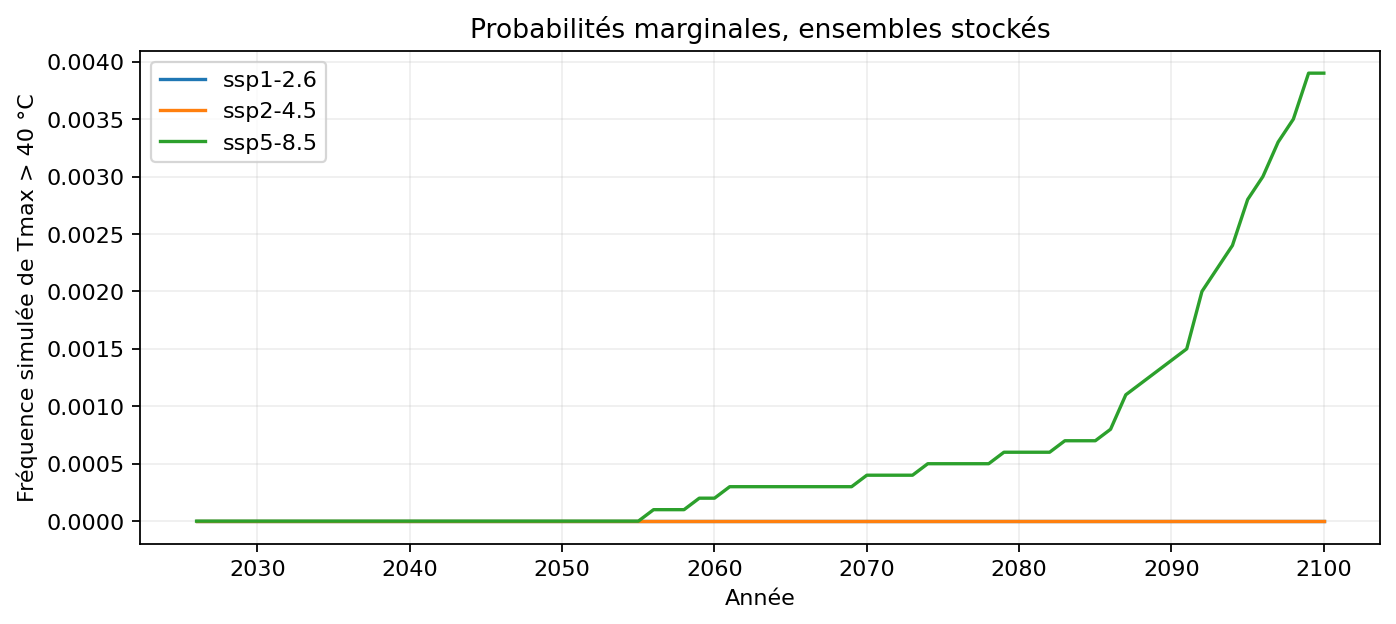

**Probabilités marginales en 2100 :** Tmax > q80 ou Tmin < q20 de l’historique 1940–2025. Ces seuils descriptifs de la phase finale diffèrent des seuils de validation et de test ajustés sur leurs trains. Les fréquences viennent des mêmes ensembles annuels stockés, sans nouvelle simulation ; l’événement Tmax > 40 °C est présenté séparément.

,variable,model,scenario,event_threshold_C,event_probability,event_definition,n
74,max,C0_direct_crps,ssp1-2.6,27.884369,0.2439,Tmax > quantile 80% historique 1940–2025,10000
149,max,C0_direct_crps,ssp2-4.5,27.884369,0.5780,Tmax > quantile 80% historique 1940–2025,10000
224,max,C0_direct_crps,ssp5-8.5,27.884369,0.9991,Tmax > quantile 80% historique 1940–2025,10000
299,min,D1_ddm_crps,ssp1-2.6,-1.858795,0.2501,Tmin < quantile 20% historique 1940–2025,10000
374,min,D1_ddm_crps,ssp2-4.5,-1.858795,0.1594,Tmin < quantile 20% historique 1940–2025,10000
449,min,D1_ddm_crps,ssp5-8.5,-1.858795,0.0502,Tmin < quantile 20% historique 1940–2025,10000


,scenario,k,n,probability,ci_lower,ci_upper,resolution
0,ssp1-2.6,0,10000,0.0000,0.000000,0.000369,0.0001
1,ssp2-4.5,2,10000,0.0002,0.000024,0.000722,0.0001
2,ssp5-8.5,29,10000,0.0029,0.001943,0.004162,0.0001


CSV complet : `artifacts\full_project\probability_40.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,scenario,k,n,probability,ci_lower,ci_upper
0,ssp1-2.6,0,10000,0.0000,0.000000,0.000369
1,ssp2-4.5,2,10000,0.0002,0.000024,0.000722
2,ssp5-8.5,455,10000,0.0455,0.041498,0.049769


CSV complet : `artifacts\full_project\trajectory_probability_40.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

k/N mesure une fréquence simulée conditionnelle au modèle. Avec k=0, il faut écrire « aucun dépassement simulé », et non une probabilité physique nulle. La résolution et l’intervalle Monte-Carlo du CSV sont numériques ; l’incertitude de la queue et l’erreur de modèle demeurent. La probabilité durant 2026–2100 suppose des résidus indépendants conditionnellement à une ancre commune sur la trajectoire.

In [11]:
show_figures('full_project', ['projection_distributions_2100', 'projection_probability_40_annual'])
show_projected_events()
probabilities = show_csv(FULL / 'probability_40.csv')
trajectories = show_csv(FULL / 'trajectory_probability_40.csv')
display(Markdown('k/N mesure une fréquence simulée conditionnelle au modèle. Avec k=0, il faut écrire « aucun dépassement simulé », et non une probabilité physique nulle. La résolution et l’intervalle Monte-Carlo du CSV sont numériques ; l’incertitude de la queue et l’erreur de modèle demeurent. La probabilité durant 2026–2100 suppose des résidus indépendants conditionnellement à une ancre commune sur la trajectoire.'))

Make the same study for the minimum annual temperatures in Brest. You can try a different approach to generate your predictions (without including the mathematical formulation).

**Diagnostics résiduels descriptifs : phase full_project.**

,variable,n,skewness,autocorrelation_lag1,autocorrelation_lag2,autocorrelation_lag3,q05_C,q50_C,q95_C
0,max,86,0.585127,0.152690,0.115651,0.000496,-3.059216,-0.443665,3.501996
1,min,86,-0.817345,0.093573,-0.012267,-0.173522,-3.638232,0.190370,2.652572


CSV complet : `artifacts\full_project\annual_analysis\residual_descriptive.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

Tmax (86 années) : asymétrie descriptive **+0.585**, quantiles q05/q50/q95 **-3.059 / -0.444 / 3.502 °C**, autocorrélations aux retards 1/2/3 ans **+0.153 / +0.116 / +0.000**. L'asymétrie positive décrit une queue empirique plus étendue vers les résidus chauds.

Tmin (86 années) : asymétrie descriptive **-0.817**, quantiles q05/q50/q95 **-3.638 / 0.190 / 2.653 °C**, autocorrélations aux retards 1/2/3 ans **+0.094 / -0.012 / -0.174**. L'asymétrie négative décrit une queue empirique plus étendue vers les résidus froids.

Ces valeurs concernent les résidus de l'ancre ajustée sur la période descriptive indiquée, et non des erreurs de validation calculées avec une ancre commune à tous les folds. Les autocorrélations décrivent une dépendance locale possible ; avec peu d'années, elles ne certifient ni indépendance, ni stationnarité, ni validité d'une queue GEV. Le bootstrap principal en blocs de trois ans conserve une partie de cette dépendance possible ; la comparaison avec des blocs d'un an est une sensibilité fixée avant le test.

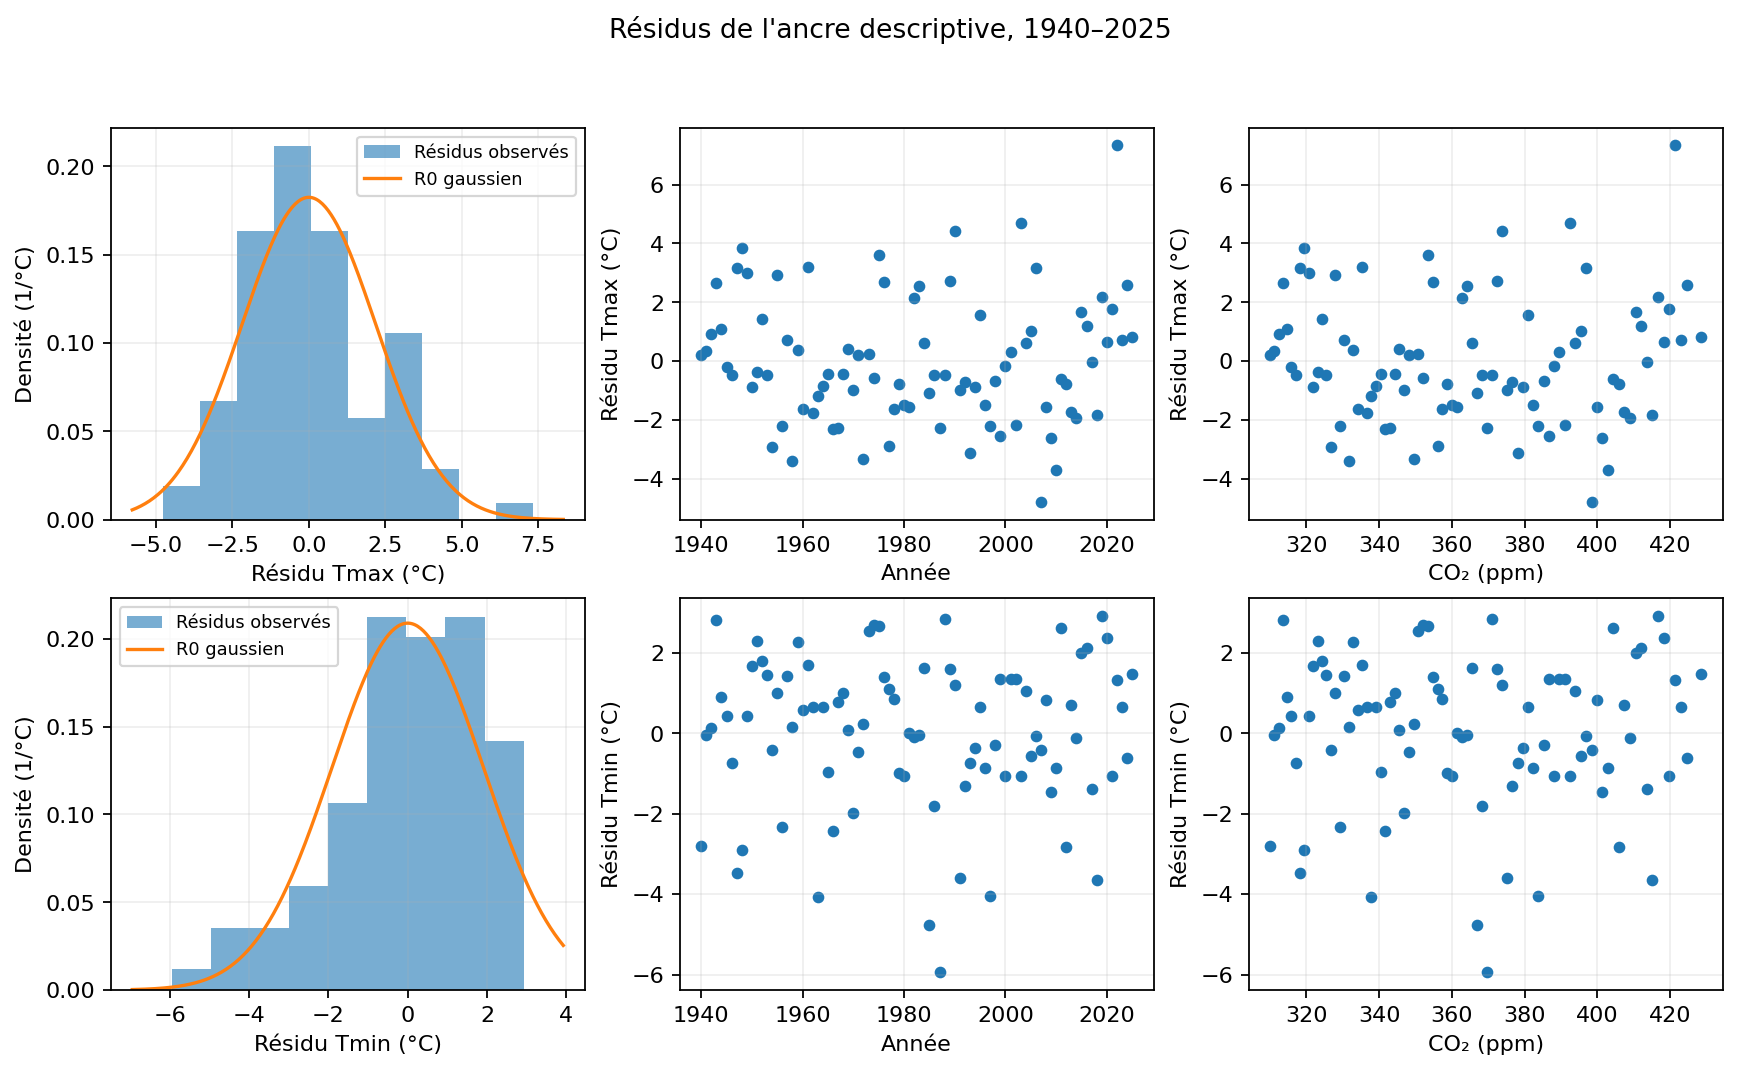

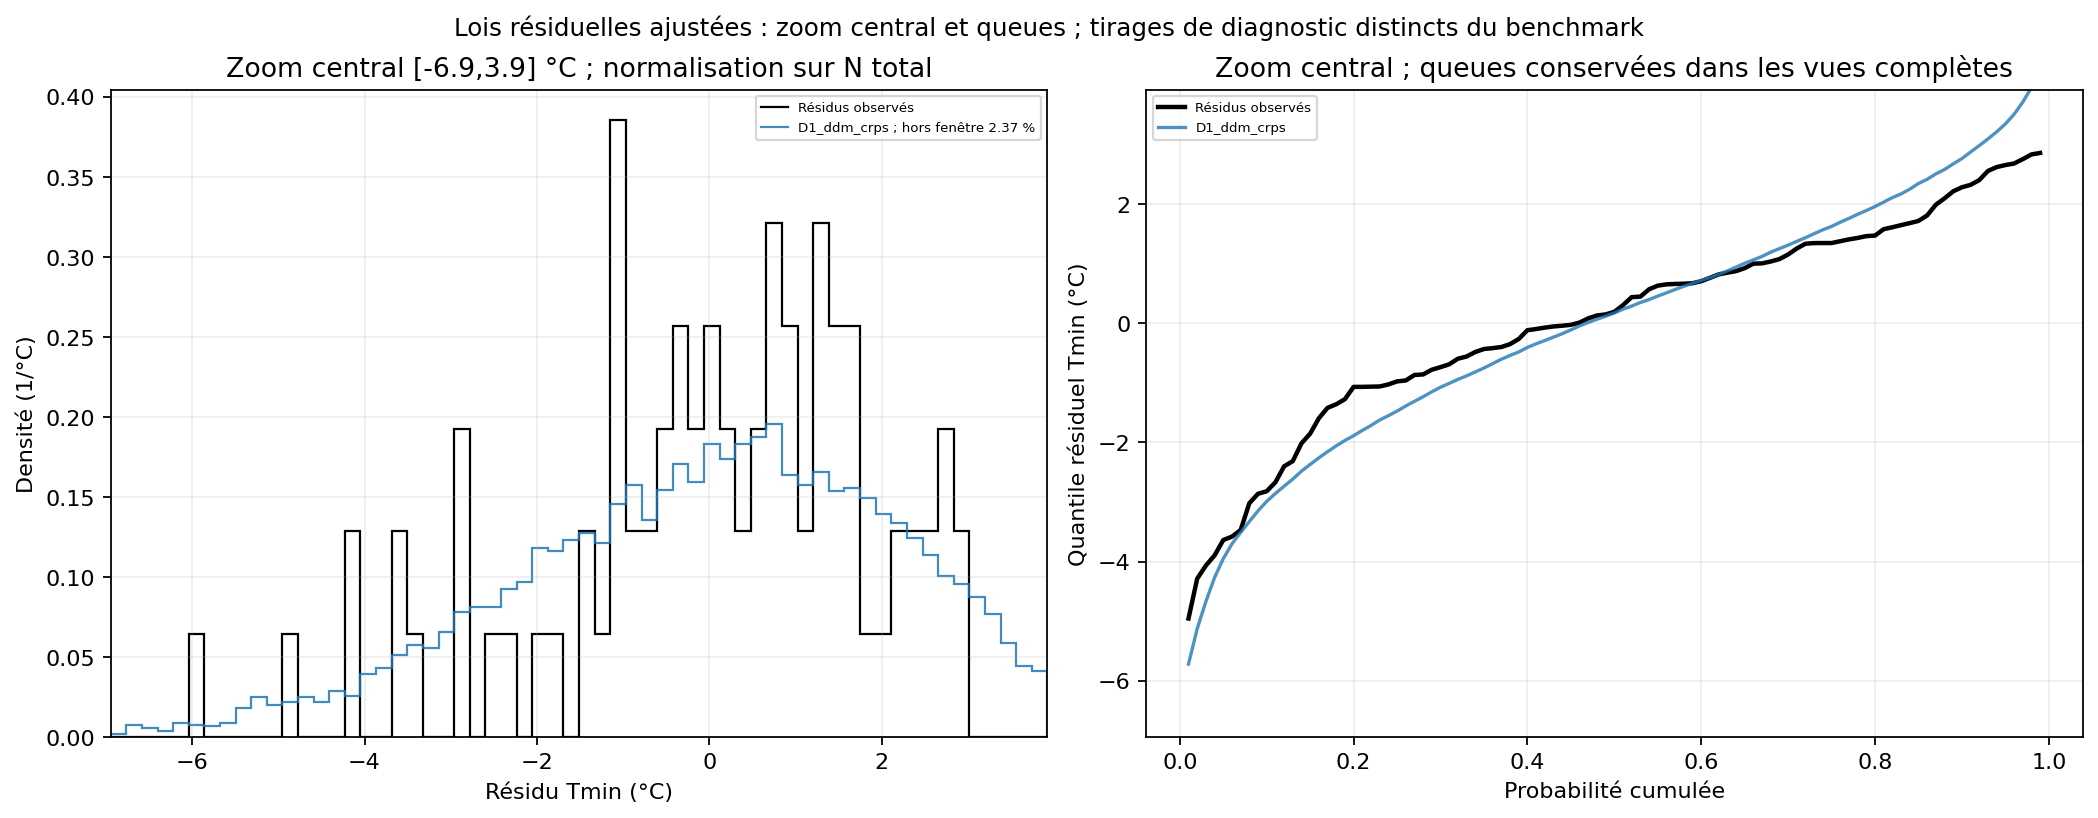

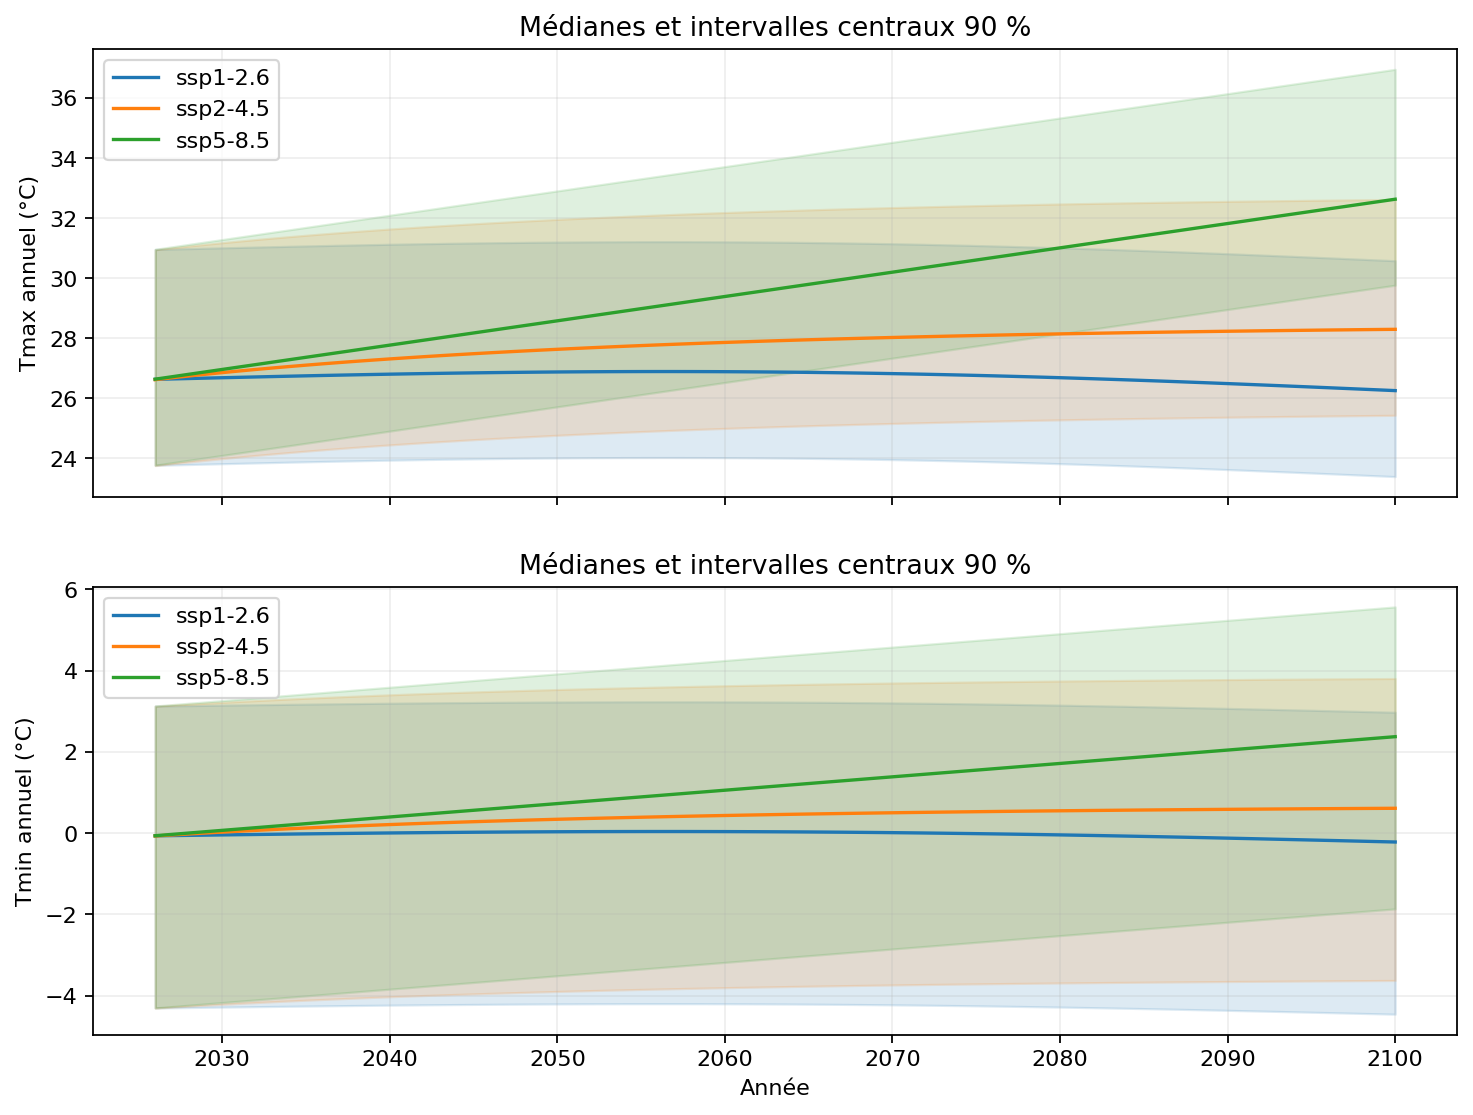

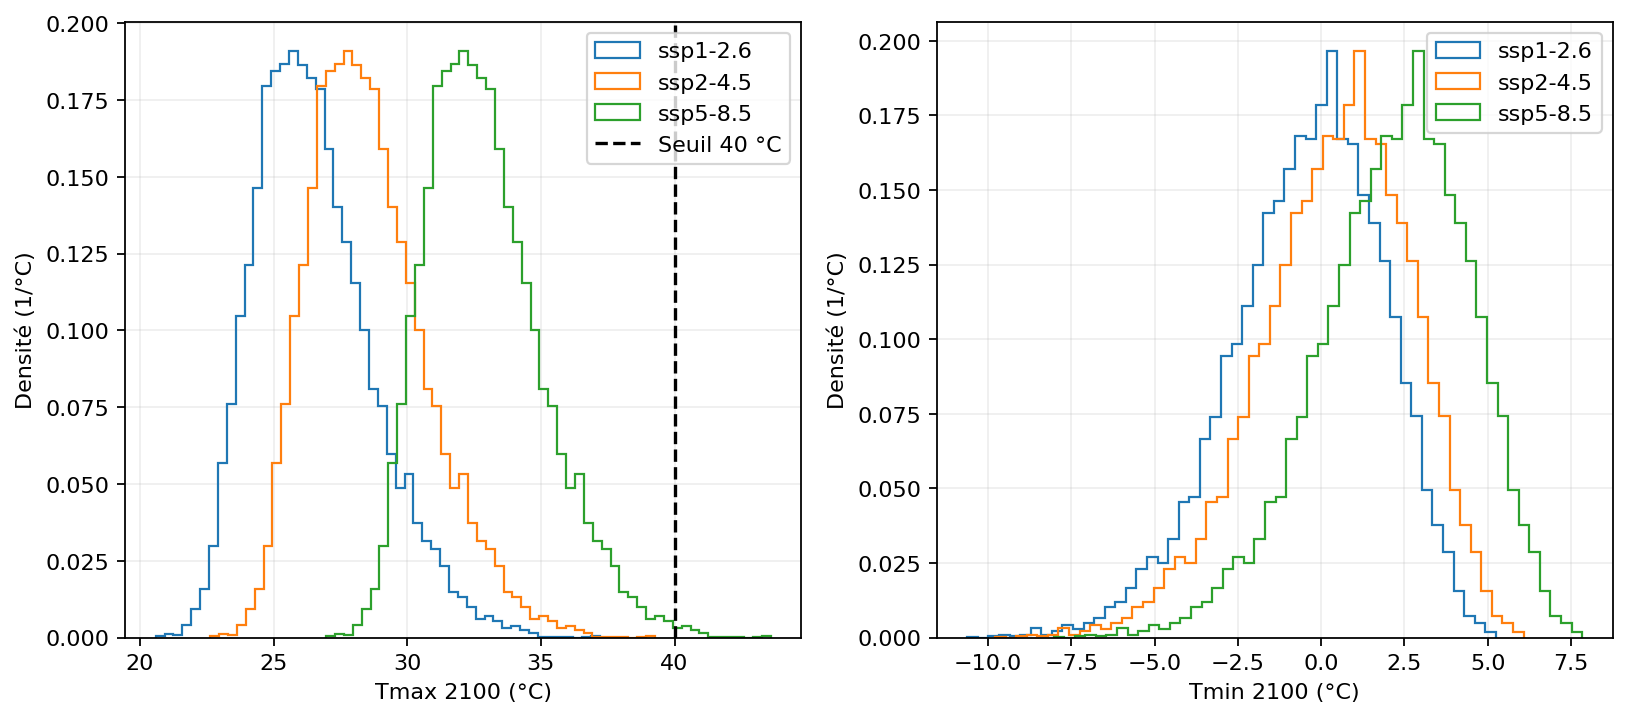

,variable,scenario,year,co2,q05,q50,q95,event_probability
0,max,ssp1-2.6,2026,420.780225,23.765833,26.630407,30.958123,0.2916
1,max,ssp1-2.6,2027,421.558613,23.779520,26.644094,30.971811,0.2944
2,max,ssp1-2.6,2028,422.333331,23.793118,26.657691,30.985408,0.2966
3,max,ssp1-2.6,2029,423.102552,23.806594,26.671168,30.998884,0.2984
4,max,ssp1-2.6,2030,423.864459,23.819918,26.684492,31.012208,0.3002
5,max,ssp1-2.6,2031,424.617247,23.833059,26.697633,31.025350,0.3016


CSV complet : `artifacts\full_project\projection_summary.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

450 lignes conservées dans le CSV complet.

Pour les minima, la GEV est ajustée à l’opposé des résidus ; la queue froide utilise h(x)=min(x,s). Les températures restent en °C. La contrainte b≥0 peut être active ; sa fréquence bootstrap indique l’importance de cette hypothèse. Le même protocole de validation précède l’ajustement final.

In [12]:
residuals_full = show_residuals('full_project')
show_png(FULL / 'annual_analysis' / 'annual_residual_diagnostics.png')
show_figures('full_project', ['residual_laws_min', 'projection_trajectories', 'projection_distributions_2100'])
show_csv(FULL / 'projection_summary.csv', 6)
display(Markdown('Pour les minima, la GEV est ajustée à l’opposé des résidus ; la queue froide utilise h(x)=min(x,s). Les températures restent en °C. La contrainte b≥0 peut être active ; sa fréquence bootstrap indique l’importance de cette hypothèse. Le même protocole de validation précède l’ajustement final.'))

## Compétition interne : distinguer train, validation et test

In [13]:
show_csv(COMP / 'benchmark_scores.csv')
show_ddpm_failure()
show_csv(COMP / 'test_diagnostics.csv')
show_csv(COMP / 'bootstrap_block_sensitivity_summary.csv')
show_csv(COMP / 'bootstrap_block_sensitivity_by_fold.csv', 40)

,model,crps_max,crps_min,admissible,errors
0,R0_exact,1.698885,1.064129,True,—
1,R0_gaussian,1.707689,1.064495,True,—
2,R1_gev,1.727800,1.036027,True,—
3,R2_empirical,1.735000,1.030154,True,—
4,D0_ddpm,1.750060,2.619998,False,min: bornes
5,C0_direct_crps,1.748986,1.027042,True,—
6,D1_ddm_crps,1.700707,1.031040,True,—
7,D2_ddm_tail,1.706913,1.014643,True,—
8,D3_ddm_anchor,1.649194,0.987842,True,—
9,D4_ddm_tail_anchor,1.654758,0.978821,True,—


CSV complet : `artifacts\competition\benchmark_scores.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

**DDPM D0 est éliminé** : 19152 valeurs de Tmin sortent de [−30,20] °C ; le minimum simulé atteint **-1933.216 °C**. Son CRPS Tmin brut est **2.619998 °C** et le kit retourne None. Un bon score de validation ne rend donc pas cette configuration admissible.

Les 684 tirages froids de la graine 2 (20.522 % de ses 3333 membres) sont réutilisés sur les 25 années de test et 3 scénarios : les 19 152 occurrences ne sont pas des anomalies climatiques indépendantes. Les graines 0 et 1 ne sortent pas des bornes. Pour la graine 2, médiane **-1.332 °C** et moyenne **-109.345 °C** révèlent une queue froide explosive. L'ancre Tmin a b=0 : l'extrapolation CO₂ n'est pas l'origine de cet échec. Le diagnostic des checkpoints décrit une amplification plausible des erreurs par la récursion DDPM et une sensibilité à la durée fixée. Il ne démontre pas qu'un entraînement plus long résoudrait le problème. Aucun entraînement, rejet, clipping ou changement de graine n'a été appliqué en réaction au test.

Détails : [diagnostic_echec_ddpm.md](<C:/Users/edlas/OneDrive/Documents/ChatGPT/Mini projet stochastique/reports/diagnostic_echec_ddpm.md>), fondé sur le NPZ et les checkpoints figés.

,variable,model,crps,twcrps,coverage80,width80,bias,brier
0,max,R0_exact,1.698885,0.728511,0.64,4.965405,-1.394732,0.342052
1,min,R0_exact,1.064129,0.154530,0.76,5.090126,-0.855062,0.128053
2,max,R0_gaussian,1.707689,0.729612,0.64,5.001831,-1.423197,0.342997
3,min,R0_gaussian,1.064495,0.152300,0.76,5.048657,-0.841032,0.123463
4,max,R1_gev,1.727800,0.724281,0.64,4.787538,-1.389278,0.347571
5,min,R1_gev,1.036027,0.149818,0.72,4.865884,-0.877177,0.107309
6,max,R2_empirical,1.735000,0.696773,0.68,5.238632,-1.374147,0.316992
7,min,R2_empirical,1.030154,0.151386,0.76,5.241699,-0.848047,0.086166
8,max,D0_ddpm,1.750060,0.720418,0.64,4.922454,-1.451058,0.342035
9,min,D0_ddpm,2.619998,1.675810,0.76,6.900454,-37.139688,0.145746


CSV complet : `artifacts\competition\test_diagnostics.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,variable,model,tail_lambda,folds,delta_crps_block1_minus3_C,delta_twcrps_block1_minus3_C,folds_global_block1_better,folds_tail_block1_better
0,max,D3_ddm_anchor,0.0,3,0.004759,0.001693,1,1
1,max,D4_ddm_tail_anchor_lambda0.5,0.5,3,0.004668,0.001626,1,1
2,max,D4_ddm_tail_anchor_lambda1,1.0,3,0.004476,0.001627,1,1
3,max,D4_ddm_tail_anchor_lambda2,2.0,3,0.004625,0.001881,1,1
4,min,D3_ddm_anchor,0.0,3,-0.008110,0.000017,2,1
5,min,D4_ddm_tail_anchor_lambda0.5,0.5,3,-0.009798,-0.000127,2,1
6,min,D4_ddm_tail_anchor_lambda1,1.0,3,-0.009923,-0.000214,2,1
7,min,D4_ddm_tail_anchor_lambda2,2.0,3,-0.010071,0.000052,2,1


CSV complet : `artifacts\competition\bootstrap_block_sensitivity_summary.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,variable,model,fold,tail_lambda,delta_crps_block1_minus3_C,delta_twcrps_block1_minus3_C
0,max,D3_ddm_anchor,F1,0.0,-0.001653,-0.000041
1,max,D4_ddm_tail_anchor_lambda0.5,F1,0.5,-0.001735,-0.000120
2,max,D4_ddm_tail_anchor_lambda1,F1,1.0,-0.002456,-0.000130
3,max,D4_ddm_tail_anchor_lambda2,F1,2.0,-0.002608,-0.000216
4,max,D3_ddm_anchor,F2,0.0,0.006052,0.004108
5,max,D4_ddm_tail_anchor_lambda0.5,F2,0.5,0.005926,0.003973
6,max,D4_ddm_tail_anchor_lambda1,F2,1.0,0.006095,0.003973
7,max,D4_ddm_tail_anchor_lambda2,F2,2.0,0.007618,0.004638
8,max,D3_ddm_anchor,F3,0.0,0.009876,0.001012
9,max,D4_ddm_tail_anchor_lambda0.5,F3,0.5,0.009811,0.001026


CSV complet : `artifacts\competition\bootstrap_block_sensitivity_by_fold.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,variable,model,tail_lambda,fold,n_years,N_block1,N_block3,crps_block1_C,crps_block3_C,delta_crps_block1_minus3_C,twcrps_block1_C,twcrps_block3_C,delta_twcrps_block1_minus3_C,source_block1
0,max,D3_ddm_anchor,0.0,F1,10,10000,10000,1.192701,1.194354,-0.001653,0.397769,0.397810,-0.000041,artifacts/competition/validation/fits/max/F1/D...
1,max,D4_ddm_tail_anchor_lambda0.5,0.5,F1,10,10000,10000,1.192324,1.194058,-0.001735,0.397729,0.397850,-0.000120,artifacts/competition/validation/fits/max/F1/D...
2,max,D4_ddm_tail_anchor_lambda1,1.0,F1,10,10000,10000,1.191149,1.193606,-0.002456,0.398335,0.398465,-0.000130,artifacts/competition/validation/fits/max/F1/D...
3,max,D4_ddm_tail_anchor_lambda2,2.0,F1,10,10000,10000,1.192384,1.194992,-0.002608,0.398125,0.398341,-0.000216,artifacts/competition/validation/fits/max/F1/D...
4,max,D3_ddm_anchor,0.0,F2,10,10000,10000,1.289092,1.283040,0.006052,0.719470,0.715362,0.004108,artifacts/competition/validation/fits/max/F2/D...
5,max,D4_ddm_tail_anchor_lambda0.5,0.5,F2,10,10000,10000,1.292465,1.286538,0.005926,0.718418,0.714446,0.003973,artifacts/competition/validation/fits/max/F2/D...
6,max,D4_ddm_tail_anchor_lambda1,1.0,F2,10,10000,10000,1.300459,1.294363,0.006095,0.719572,0.715599,0.003973,artifacts/competition/validation/fits/max/F2/D...
7,max,D4_ddm_tail_anchor_lambda2,2.0,F2,10,10000,10000,1.344655,1.337037,0.007618,0.730795,0.726157,0.004638,artifacts/competition/validation/fits/max/F2/D...
8,max,D3_ddm_anchor,0.0,F3,10,10000,10000,0.865275,0.855399,0.009876,0.022568,0.021556,0.001012,artifacts/competition/validation/fits/max/F3/D...
9,max,D4_ddm_tail_anchor_lambda0.5,0.5,F3,10,10000,10000,0.864091,0.854280,0.009811,0.021873,0.020847,0.001026,artifacts/competition/validation/fits/max/F3/D...


La sensibilité du bootstrap compare blocs de 1 et 3 ans sur les folds de validation 1940–2000, séparément pour chaque variable et λ. Un delta négatif favorise les blocs d'un an. Les blocs de trois ans restent la convention principale fixée avant le test. Les diagnostics des résidus 1940–2025 ci-dessus sont descriptifs et ne constituent pas ces scores de validation.

## Discussion et partage de l'équipe

Les simulations ne créent pas de nouvelles années d'observations. L'extrapolation suppose une loi résiduelle stationnaire et une ancre log-linéaire. Le littoral et la variabilité atmosphérique/océanique ne sont pas modélisés explicitement. La queue à 40 °C reste fragile, même avec un bon CRPS historique.

In [14]:
path = ROOT / 'reports' / 'synthese_equipe.md'
if path.exists():
    display(Markdown(path.read_text(encoding='utf-8')))

# Synthèse équipe


Candidat verrouillé : Tmax **C0_direct_crps**, Tmin **D1_ddm_crps**. Les choix sont fixés sur validation 1940–2000 avant ouverture du test.


Résultats réels du benchmark (°C pour les CRPS) :


| model | crps_max | crps_min | admissible | errors |
| --- | --- | --- | --- | --- |
| R0_exact | 1.69889 | 1.06413 | True | — |
| R0_gaussian | 1.70769 | 1.06449 | True | — |
| R1_gev | 1.7278 | 1.03603 | True | — |
| R2_empirical | 1.735 | 1.03015 | True | — |
| D0_ddpm | 1.75006 | 2.62 | False | min: bornes |
| C0_direct_crps | 1.74899 | 1.02704 | True | — |
| D1_ddm_crps | 1.70071 | 1.03104 | True | — |
| D2_ddm_tail | 1.70691 | 1.01464 | True | — |
| D3_ddm_anchor | 1.64919 | 0.987842 | True | — |
| D4_ddm_tail_anchor | 1.65476 | 0.978821 | True | — |
| participant | 1.74899 | 1.03104 | True | — |


Participant **participant** : CRPS Tmax **1.748986 °C**, Tmin **1.031040 °C** ; statut **admissible**.

**DDPM D0 est éliminé** : 19152 valeurs de Tmin sortent de [−30,20] °C ; le minimum simulé atteint **-1933.216 °C**. Son CRPS Tmin brut est **2.619998 °C** et le kit retourne None. Un bon score de validation ne rend donc pas cette configuration admissible.

Détails : [diagnostic_echec_ddpm.md](diagnostic_echec_ddpm.md), fondé sur le NPZ et les checkpoints figés.


Tmax > 40 °C en 2100, conditionnellement au modèle : ssp1-2.6 **0/10000 (0.000 %)**; ssp2-4.5 **2/10000 (0.020 %)**; ssp5-8.5 **29/10000 (0.290 %)**. Avec zéro tirage dépassant 40 °C, aucun dépassement n'est simulé ; la borne Monte-Carlo à 95 % est 0,000369, pas une probabilité physique nulle.


Vagues de chaleur descriptives 1940–2025 : **421 événements ≥ 3 jours**, **798 ≥ 2 jours** ; durée maximale **14 jours**.


Les 25 années de test et les 61 années d'apprentissage limitent la précision des conclusions. Le CO₂ sert de covariable de tendance ; la stabilité des résidus et l'extrapolation jusqu'à 2100 restent des hypothèses. La simulation de 40 °C ne valide pas la queue physique.


À partager localement : les deux rapports, les notebooks exécutés, les PNG/SVG, les CSV/JSON et les NPZ officiels ; conserver configs, checkpoints et empreintes pour reproduction.


## Références méthodologiques

- [DDPM](https://arxiv.org/abs/2006.11239) et [calendrier cosinus](https://arxiv.org/abs/2102.09672).
- [Diffusion et scores probabilistes météo, prépublication](https://arxiv.org/html/2609.38632v1) ; adaptation scalaire explicitée ci-dessus.
- [AIFS-CRPS](https://arxiv.org/html/2412.15832v1) et [estimateurs CRPS](https://scoringrules.readthedocs.io/en/latest/crps_estimators.html).
- [Scores pondérés](https://scoringrules.readthedocs.io/en/latest/weighted_scores.html).
- [GEV et covariable CO₂](https://ascmo.copernicus.org/articles/9/45/2023/).
- [Validation chronologique](https://otexts.com/fpp3/tscv.html).

Ces références méthodologiques ne fournissent aucune observation supplémentaire au modèle.

La provenance exacte des CSV n'est pas certifiée par leurs métadonnées. La documentation ECMWF
décrit [ERA5 HRES à environ 31 km](https://confluence.ecmwf.int/pages/viewpage.action?navigatingVersions=true&pageId=78296807)
et [ERA5-Land à environ 9 km](https://www.ecmwf.int/en/era5-land). La mention 9 km du starter
ne suffit donc pas à identifier le produit fourni. Les consultations et leurs limites figurent dans `reports/audit_sources.md`.
